<a href="https://colab.research.google.com/github/Sayak-coder/HateSpeech-detection/blob/main/5_models_classification_report_(EN).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install nltk

In [38]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 61.0 MB/s  0:00:00


In [50]:
import pandas as pd
import numpy as np
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import re
import gensim
from gensim.models import Word2Vec
import gensim.downloader as api

In [7]:
df_en = pd.read_csv('/content/StereoQueerEval_EN_training.tsv', sep='\t')
df_en.head()

,StereoQueerEval_id,yt_title,yt_description,yt_comment,stereotype,hate_speech,target
0,training_EN_0001,[CHANNEL]: Lesbian denied communion at funeral,[CHANNEL] speaks to Barbara Johnson who says a...,She's living in unrepentant defiance to God's ...,yes,yes_explicit,individual_l
1,training_EN_0002,GOP Congresswoman uses anti-trans slur in Hous...,Rep. Nancy Mace (R-SC) was challenged by Rep. ...,Rep Mace: Keep on being dedicated to truth and...,yes,yes_implicit,group_t
2,training_EN_0003,Kevin Smith defends his gay brother,"Kevin Smith supports gay rights, and defends h...","We all need Jesus, He said no homosexual shall...",yes,yes_implicit,"group_l,g"
3,training_EN_0004,Judge removes child from gay foster parents,A Utah judge removed a foster child from a les...,So can two black men adopt a little white girl...,yes,yes_implicit,group_l
4,training_EN_0005,Chechen leader Ramzan Kadyrov questioned on 'g...,Chechnya's leader Ramzan Kadyrov is questioned...,Of course west and US will hate him,yes,yes_implicit,group_g


In [35]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [8]:
df = df_en[['yt_comment','stereotype']]

In [9]:
df.head()

,yt_comment,stereotype
0,She's living in unrepentant defiance to God's ...,yes
1,Rep Mace: Keep on being dedicated to truth and...,yes
2,"We all need Jesus, He said no homosexual shall...",yes
3,So can two black men adopt a little white girl...,yes
4,Of course west and US will hate him,yes


In [28]:
sentences=[]
for i in range(len(df['yt_comment'])):
  sentence = nltk.sent_tokenize(df['yt_comment'][i])
  sentences.append(sentence)
sentences

[["She's living in unrepentant defiance to God's moral law."],
 ['Rep Mace: Keep on being dedicated to truth and NOT politically correct propaganda!',
  'Thank you for your leadership.'],
 ['We all need Jesus, He said no homosexual shall inherit the Kingdom of God.',
  'The afterlife is real and I experienced it and Jesus really is God.'],
 ['So can two black men adopt a little white girl ?',
  'Exactly the law isn’t fair an yet y’all want all the rights.'],
 ['Of course west and US will hate him'],
 ['For God, so loved the world that he gave his one and only begotten son, that whoever shall believe in him will not perish, but have eternal life.',
  'when we become adopted in the union through the blood of Jesus, when we become baptized, we are then cleansed by all unrighteousness, and we become right to the eyes of the father, which means we are saved not by our works but by grace through faith, so when we are given the Holy Spirit, then what the spirit aligns with, us, we want to ali

In [36]:
lemmatizer = WordNetLemmatizer()
corpus=[]

stop_words = set(stopwords.words('english'))

for i in range(len(sentences)):
    full_text = ' '.join(sentences[i])
    review = re.sub('[^a-zA-Z]', ' ', full_text)
    review = review.lower()

    words = word_tokenize(review)
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words]

    corpus.append(' '.join(words))

In [37]:
corpus[1]

'rep mace keep dedicated truth politically correct propaganda thank leadership'

In [42]:
wv = api.load('word2vec-google-news-300')

[==================================================] 100.0% 1662.8/1662.8MB downloaded


In [51]:
sent_vectors = []

for sentence in corpus:
    vecs = [wv[word] for word in sentence.split() if word in wv]
    if vecs:
        sent_vec = np.mean(vecs, axis=0)
    else:
        sent_vec = np.zeros(wv.vector_size)
    sent_vectors.append(sent_vec)

X = np.array(sent_vectors)

In [53]:
X

array([[ 0.18277995,  0.03438823,  0.09562174, ..., -0.06494141,
         0.12727864,  0.09712728],
       [ 0.05249939, -0.03032226, -0.02394409, ...,  0.01071777,
         0.01628418,  0.1148731 ],
       [ 0.08365958,  0.02729143, -0.03889683, ..., -0.14123099,
        -0.01169259,  0.08014788],
       ...,
       [ 0.10810547, -0.01860351, -0.04438477, ..., -0.09243164,
        -0.00290527, -0.0935791 ],
       [ 0.10673828,  0.03508301,  0.04006348, ..., -0.13300781,
         0.03100128, -0.06235351],
       [ 0.03016663, -0.04191081, -0.0019633 , ..., -0.10339483,
        -0.00744629,  0.018514  ]], shape=(2989, 300))

In [55]:
y = df['stereotype'].map({'no':0,'yes':1})
y.head()

,stereotype
0,1
1,1
2,1
3,1
4,1


In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=45)

In [57]:
X_train.shape, X_test.shape

((2391, 300), (598, 300))

Logistic Regression

In [58]:
from sklearn.metrics import accuracy_score, classification_report

In [85]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))

0.6688963210702341
              precision    recall  f1-score   support

           0       0.68      0.76      0.72       329
           1       0.65      0.56      0.60       269

    accuracy                           0.67       598
   macro avg       0.67      0.66      0.66       598
weighted avg       0.67      0.67      0.67       598



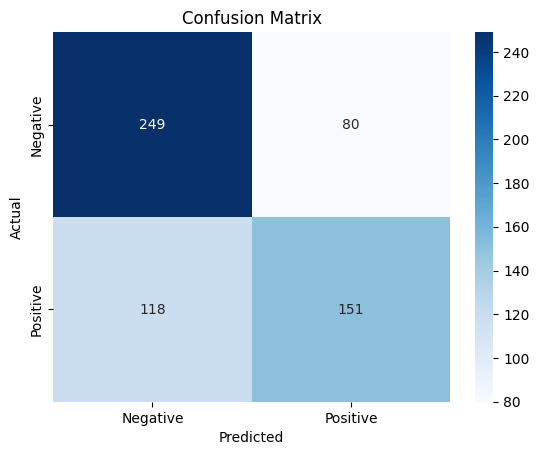

In [86]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

RandomForestClassifier


In [87]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))

0.6822742474916388
              precision    recall  f1-score   support

           0       0.67      0.84      0.74       329
           1       0.71      0.49      0.58       269

    accuracy                           0.68       598
   macro avg       0.69      0.67      0.66       598
weighted avg       0.69      0.68      0.67       598



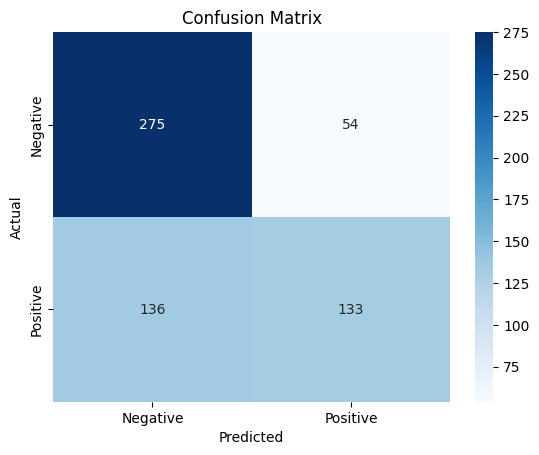

In [88]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

XGBoost

In [89]:
from xgboost import XGBClassifier

model = XGBClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))

0.6939799331103679
              precision    recall  f1-score   support

           0       0.70      0.77      0.73       329
           1       0.68      0.60      0.64       269

    accuracy                           0.69       598
   macro avg       0.69      0.69      0.69       598
weighted avg       0.69      0.69      0.69       598



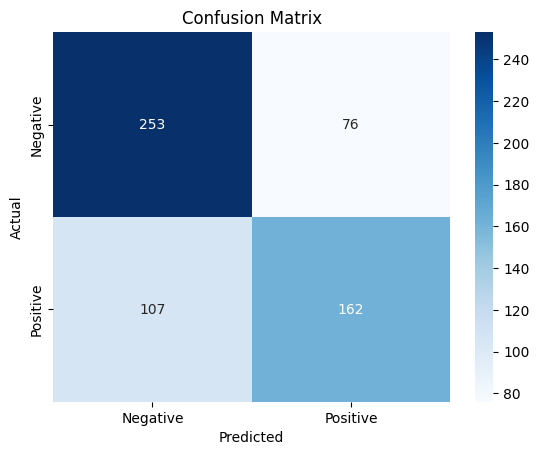

In [90]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

LSTM RNN

In [80]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

In [91]:
embedding_vector_features=40
max_length=30
voc_size = 5000

model=Sequential()
model.add(Embedding(voc_size,embedding_vector_features,input_length=max_length))
model.add(Dropout(0.3))
model.add(LSTM(32))
model.add(Dropout(0.3))
model.add(Dense(1,activation='sigmoid'))
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [92]:
epochs=5
model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=epochs,batch_size=64)

Epoch 1/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 194ms/step - accuracy: 0.5479 - loss: 0.6889 - val_accuracy: 0.5502 - val_loss: 0.6883
Epoch 2/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 6s 156ms/step - accuracy: 0.5579 - loss: 0.6869 - val_accuracy: 0.5502 - val_loss: 0.6886
Epoch 3/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 11s 181ms/step - accuracy: 0.5579 - loss: 0.6863 - val_accuracy: 0.5502 - val_loss: 0.6881
Epoch 4/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 11s 197ms/step - accuracy: 0.5579 - loss: 0.6873 - val_accuracy: 0.5502 - val_loss: 0.6881
Epoch 5/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 172ms/step - accuracy: 0.5579 - loss: 0.6879 - val_accuracy: 0.5502 - val_loss: 0.6884


In [93]:
y_pred=model.predict(X_test)
y_pred=np.where(y_pred>0.5,1,0)

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step


In [94]:
print(accuracy_score(y_pred,y_test))
print(classification_report(y_pred,y_test))

0.5501672240802675
              precision    recall  f1-score   support

           0       1.00      0.55      0.71       598
           1       0.00      0.00      0.00         0

    accuracy                           0.55       598
   macro avg       0.50      0.28      0.35       598
weighted avg       1.00      0.55      0.71       598



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


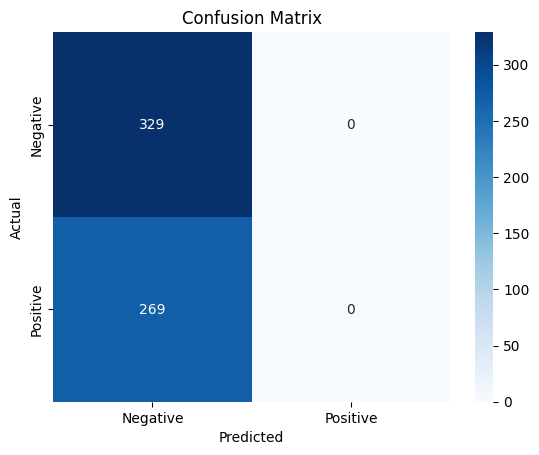

In [95]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

MultinomialNB

In [99]:
lemmatized_sent = []
for i in range(len(corpus)):
  lemmatized_sent.append(corpus[i])

X_train,X_test,y_train,y_test = train_test_split(lemmatized_sent, y, test_size=0.2, random_state=45)

In [100]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
X_train = cv.fit_transform(X_train)
X_test = cv.transform(X_test)

In [101]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))

0.7023411371237458
              precision    recall  f1-score   support

           0       0.74      0.72      0.73       329
           1       0.66      0.68      0.67       269

    accuracy                           0.70       598
   macro avg       0.70      0.70      0.70       598
weighted avg       0.70      0.70      0.70       598



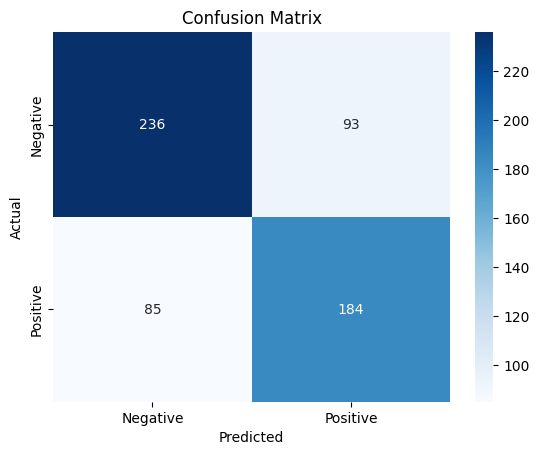

In [102]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()